# Campaign impact and statistical testing

Did each marketing campaign create value, and are the observed differences statistically
meaningful?

**Experiment design (from the data model).** Each campaign randomised its audience into a
treatment arm and a holdout (control) arm. Order-level attribution is only ever recorded for
exposed treatment customers inside the campaign window, and the comparison group is the
randomised holdout.

**Unit of analysis.** One row per **assigned customer** per campaign, taken from
`analytics.mart_campaign_customer_outcomes`. The outcome is recognised net revenue inside the
campaign window. Orders are not treated as independent observations, because one customer can
place several orders.

**Primary comparison.** Intention-to-treat: everyone randomised to treatment versus everyone
randomised to holdout, whether or not they were exposed. This is the comparison that preserves
the randomisation; exposure-only analysis is available but is not the headline.

**No ground truth.** The generation manifest contains the true lift that was designed into the
data. It is not loaded, read or referenced by any calculation below; the only cell that touches
it is the clearly marked post-hoc validation at the end.

In [1]:
import pandas as pd
from IPython.display import Image, display

from novacart.analytics.campaigns import (
    PRACTICAL_ABSOLUTE_THRESHOLD,
    PRACTICAL_RELATIVE_THRESHOLD,
    campaign_comparison,
    campaign_statistics,
    significance_overview,
)
from novacart.analytics.common import load_analysis_inputs
from novacart.analytics.plots import (
    FIGURE_FILENAMES,
    plot_campaign_confidence_intervals,
    plot_campaign_lift_comparison,
    plot_campaign_significance_overview,
    save_figure,
)
from novacart.analytics.statistics import FDR_Q

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 1. Statistical method (fixed before looking at results)

| Choice | Method | Why |
| --- | --- | --- |
| Test | Welch's two-sample t-test on customer-level revenue | Two independent groups, unequal sizes and variances; the central limit theorem covers a skewed revenue distribution at these sample sizes |
| Interval | 95% confidence interval for the difference in means (Welch-Satterthwaite) | Standard companion to the test, and directly readable as a range of plausible lifts |
| Robustness | Percentile bootstrap interval and Mann-Whitney U p-value | Check that the conclusion is not an artefact of skew or a few very large customers |
| Effect size | Hedges' g (bias-corrected Cohen's d) | Standardised magnitude, comparable across campaigns |
| Multiplicity | Benjamini-Hochberg FDR at 5% across the 20 campaigns | Controls the share of false discoveries while keeping useful power, unlike a Bonferroni-style correction |

**Statistical vs practical significance.** A campaign is *statistically significant* when the
FDR-adjusted p-value is below 0.05. It is *practically significant* when the relative lift is
at least **10%** and the absolute lift is at least **EUR 5.00** per assigned customer. Both
flags are reported separately: a precisely estimated but tiny difference is not a reason to act.

## 2. Descriptive comparison

In [2]:
inputs = load_analysis_inputs()
outcomes = inputs.campaign_outcomes
print(f"assigned customers      : {len(outcomes):,}")
print(f"campaigns               : {outcomes['campaign_id'].nunique():,}")
print(f"treatment / holdout     : {int((outcomes['arm'] == 'treatment').sum()):,} / {int((outcomes['arm'] == 'control').sum()):,}")

comparison = campaign_comparison(outcomes)
comparison[
    ["campaign_id", "objective", "treatment_n", "control_n", "treatment_mean", "control_mean",
     "absolute_difference", "relative_difference"]
].style.format(
    {
        "treatment_mean": "EUR {:,.2f}",
        "control_mean": "EUR {:,.2f}",
        "absolute_difference": "EUR {:+,.2f}",
        "relative_difference": "{:+.1%}",
    }
)

assigned customers      : 44,090
campaigns               : 20
treatment / holdout     : 31,707 / 12,383


,campaign_id,objective,treatment_n,control_n,treatment_mean,control_mean,absolute_difference,relative_difference
0,CMP-001,retention,1700,657,EUR 319.54,EUR 330.15,EUR -10.61,-3.2%
1,CMP-002,acquisition,1018,363,EUR 44.17,EUR 32.61,EUR +11.56,+35.4%
2,CMP-003,acquisition,1008,396,EUR 260.94,EUR 195.07,EUR +65.87,+33.8%
3,CMP-004,acquisition,1076,390,EUR 101.52,EUR 114.63,EUR -13.10,-11.4%
4,CMP-005,retention,1919,794,EUR 325.43,EUR 214.58,EUR +110.86,+51.7%
5,CMP-006,reactivation,409,192,EUR 52.23,EUR 17.90,EUR +34.33,+191.8%
6,CMP-007,reactivation,927,359,EUR 20.16,EUR 29.31,EUR -9.16,-31.2%
7,CMP-008,brand,4523,1773,EUR 130.05,EUR 127.97,EUR +2.08,+1.6%
8,CMP-009,cross_sell,3595,1383,EUR 174.68,EUR 109.34,EUR +65.33,+59.8%
9,CMP-010,brand,1292,498,EUR 94.23,EUR 113.48,EUR -19.25,-17.0%


## 3. Test results

`adjusted_p_value` applies the Benjamini-Hochberg correction across all campaigns in the table,
so the significance flags account for testing 20 campaigns at once.

In [3]:
statistics = campaign_statistics(outcomes)
statistics[
    ["campaign_id", "objective", "treatment_n", "control_n", "treatment_mean", "control_mean",
     "absolute_difference", "relative_difference", "confidence_interval_low",
     "confidence_interval_high", "p_value", "adjusted_p_value", "effect_size",
     "effect_size_label", "statistically_significant", "practically_significant"]
].style.format(
    {
        "treatment_mean": "EUR {:,.2f}",
        "control_mean": "EUR {:,.2f}",
        "absolute_difference": "EUR {:+,.2f}",
        "relative_difference": "{:+.1%}",
        "confidence_interval_low": "EUR {:+,.2f}",
        "confidence_interval_high": "EUR {:+,.2f}",
        "p_value": "{:.2e}",
        "adjusted_p_value": "{:.2e}",
        "effect_size": "{:+.3f}",
    }
)

,campaign_id,objective,treatment_n,control_n,treatment_mean,control_mean,absolute_difference,relative_difference,confidence_interval_low,confidence_interval_high,p_value,adjusted_p_value,effect_size,effect_size_label,statistically_significant,practically_significant
0,CMP-001,retention,1700,657,EUR 319.54,EUR 330.15,EUR -10.61,-3.2%,EUR -55.07,EUR +33.84,6.40e-01,7.11e-01,-0.021,negligible,False,False
1,CMP-002,acquisition,1018,363,EUR 44.17,EUR 32.61,EUR +11.56,+35.4%,EUR -4.04,EUR +27.16,1.46e-01,2.66e-01,+0.082,negligible,False,True
2,CMP-003,acquisition,1008,396,EUR 260.94,EUR 195.07,EUR +65.87,+33.8%,EUR +1.53,EUR +130.22,4.48e-02,9.96e-02,+0.112,negligible,False,True
3,CMP-004,acquisition,1076,390,EUR 101.52,EUR 114.63,EUR -13.10,-11.4%,EUR -49.94,EUR +23.73,4.85e-01,6.47e-01,-0.042,negligible,False,False
4,CMP-005,retention,1919,794,EUR 325.43,EUR 214.58,EUR +110.86,+51.7%,EUR +75.16,EUR +146.55,1.37e-09,1.37e-08,+0.236,small,True,True
5,CMP-006,reactivation,409,192,EUR 52.23,EUR 17.90,EUR +34.33,+191.8%,EUR +7.79,EUR +60.87,1.13e-02,3.23e-02,+0.179,negligible,True,True
6,CMP-007,reactivation,927,359,EUR 20.16,EUR 29.31,EUR -9.16,-31.2%,EUR -28.66,EUR +10.35,3.57e-01,5.10e-01,-0.071,negligible,False,False
7,CMP-008,brand,4523,1773,EUR 130.05,EUR 127.97,EUR +2.08,+1.6%,EUR -16.20,EUR +20.36,8.24e-01,8.24e-01,+0.006,negligible,False,False
8,CMP-009,cross_sell,3595,1383,EUR 174.68,EUR 109.34,EUR +65.33,+59.8%,EUR +47.95,EUR +82.71,2.15e-13,4.31e-12,+0.209,small,True,True
9,CMP-010,brand,1292,498,EUR 94.23,EUR 113.48,EUR -19.25,-17.0%,EUR -47.71,EUR +9.21,1.85e-01,3.08e-01,-0.076,negligible,False,False


In [4]:
overview = significance_overview(statistics)
print(f"FDR level (q)           : {FDR_Q:.0%}")
overview

FDR level (q)           : 5%


,category,campaigns
0,campaigns tested,20
1,statistically significant (FDR 5%),8
2,practically significant (>=10% and >= EUR 5),11
3,both statistical and practical,8
4,positive point estimate,13


### Plain-language interpretation of every campaign

In [5]:
statistics[["campaign_id", "business_interpretation"]]

,campaign_id,business_interpretation
0,CMP-001,No detectable difference between treatment and...
1,CMP-002,Directionally positive but not statistically s...
2,CMP-003,Directionally positive but not statistically s...
3,CMP-004,No detectable difference between treatment and...
4,CMP-005,Statistically significant and materially posit...
5,CMP-006,Statistically significant and materially posit...
6,CMP-007,No detectable difference between treatment and...
7,CMP-008,No detectable difference between treatment and...
8,CMP-009,Statistically significant and materially posit...
9,CMP-010,No detectable difference between treatment and...


## 4. Figures

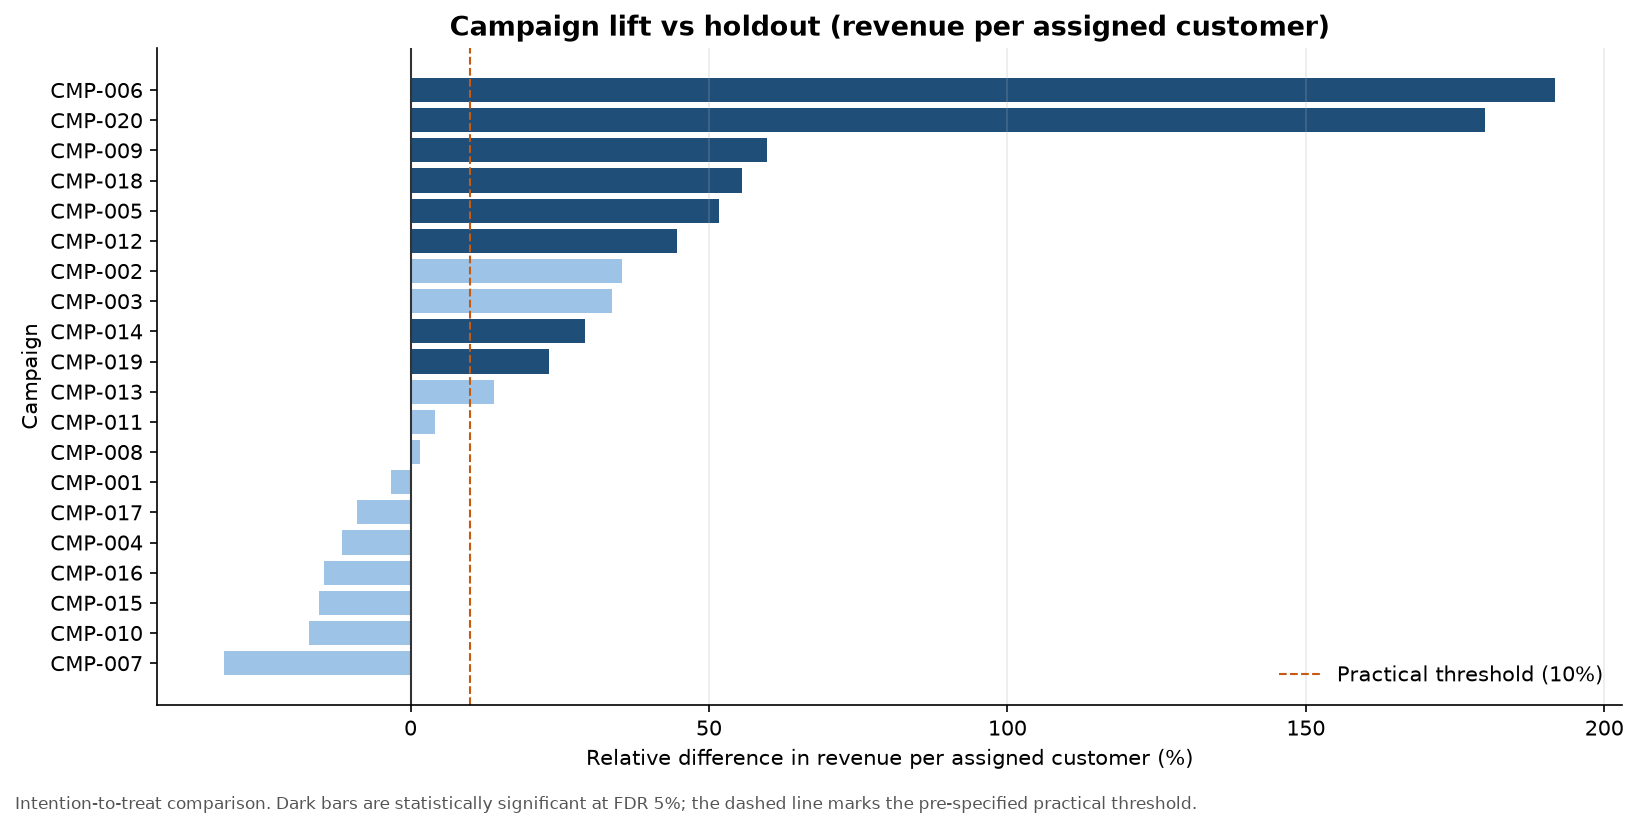

In [6]:
figures = {
    "campaign_lift_comparison": save_figure(
        plot_campaign_lift_comparison(statistics),
        FIGURE_FILENAMES["campaign_lift_comparison"],
    ),
    "campaign_confidence_intervals": save_figure(
        plot_campaign_confidence_intervals(statistics),
        FIGURE_FILENAMES["campaign_confidence_intervals"],
    ),
    "campaign_significance_overview": save_figure(
        plot_campaign_significance_overview(statistics),
        FIGURE_FILENAMES["campaign_significance_overview"],
    ),
}
display(Image(filename=str(figures["campaign_lift_comparison"])))

**How precise is each estimate?** Intervals that cross zero are inconclusive, however large the
point estimate looks.

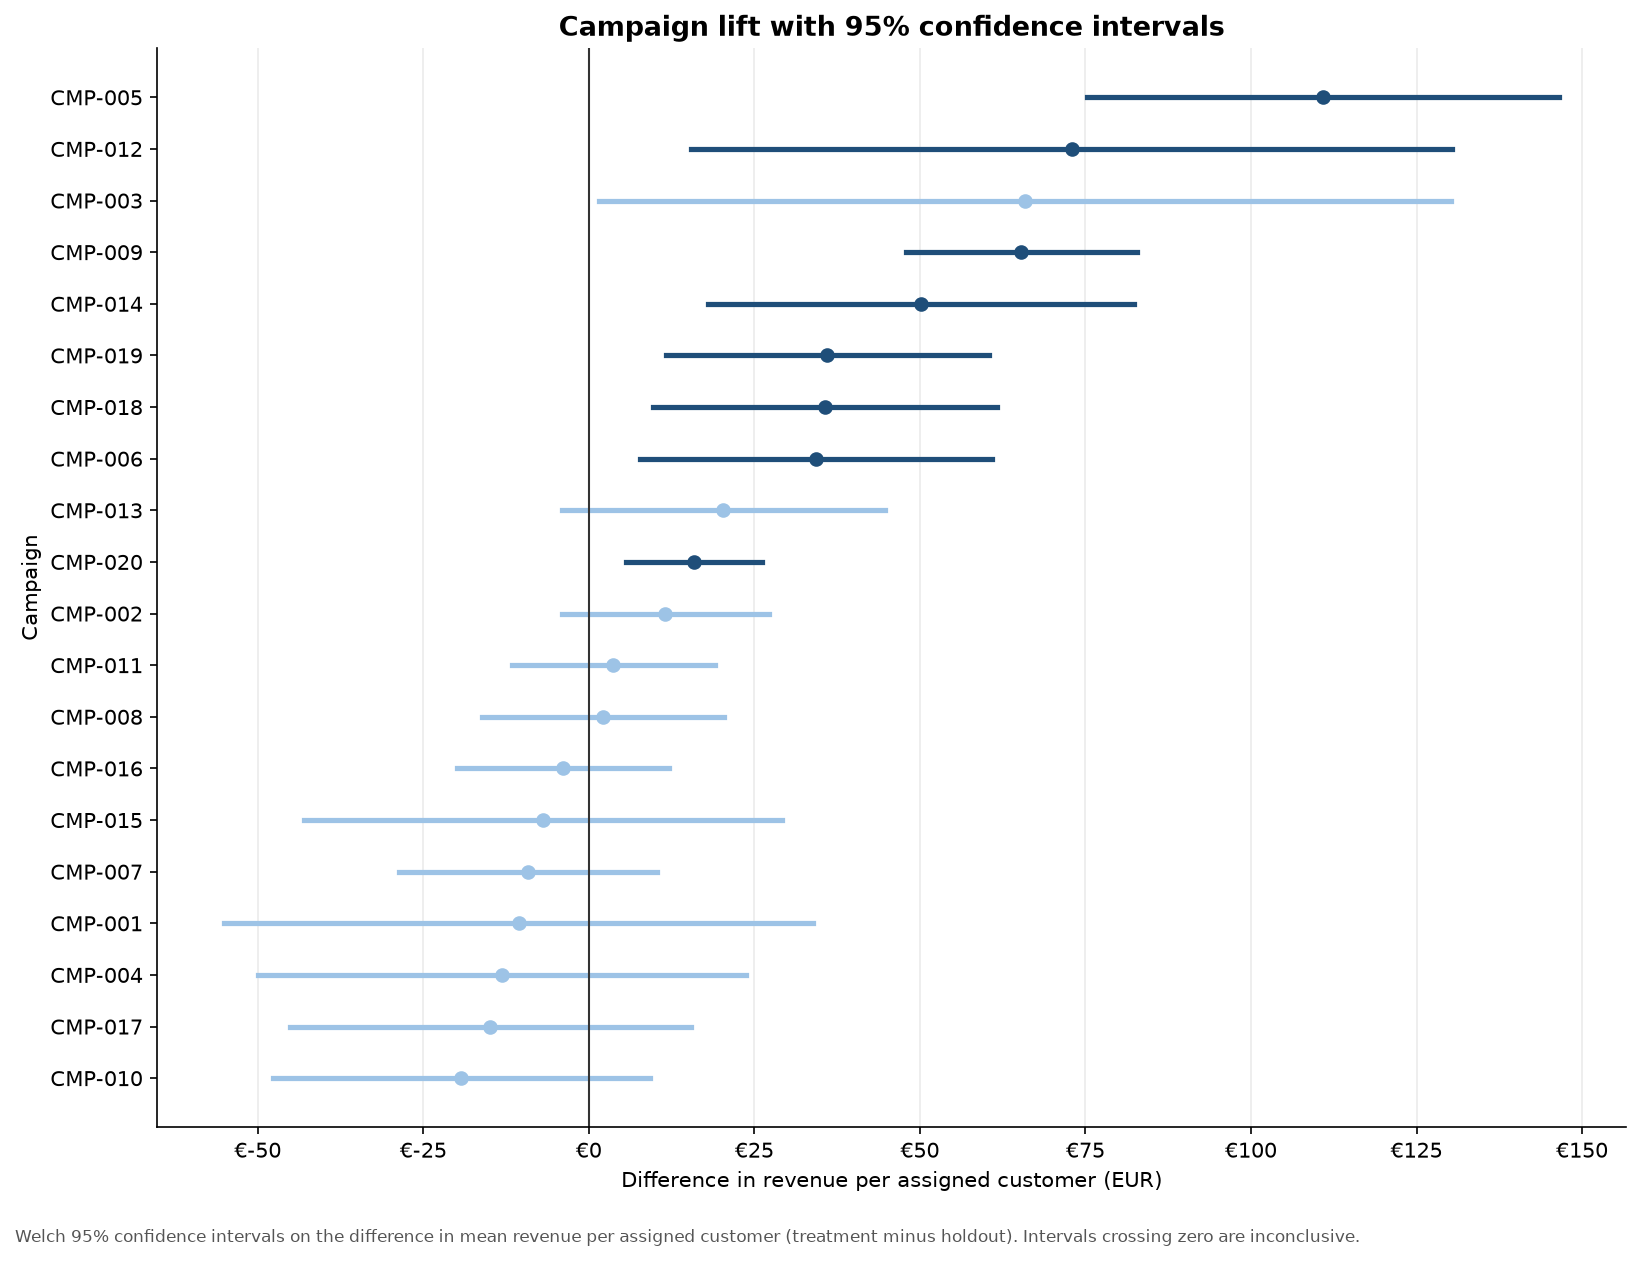

In [7]:
display(Image(filename=str(figures["campaign_confidence_intervals"])))

**Statistical versus practical significance.** The horizontal axis is the lift; the vertical
axis is the evidence. Only the top-right region justifies an action decision.

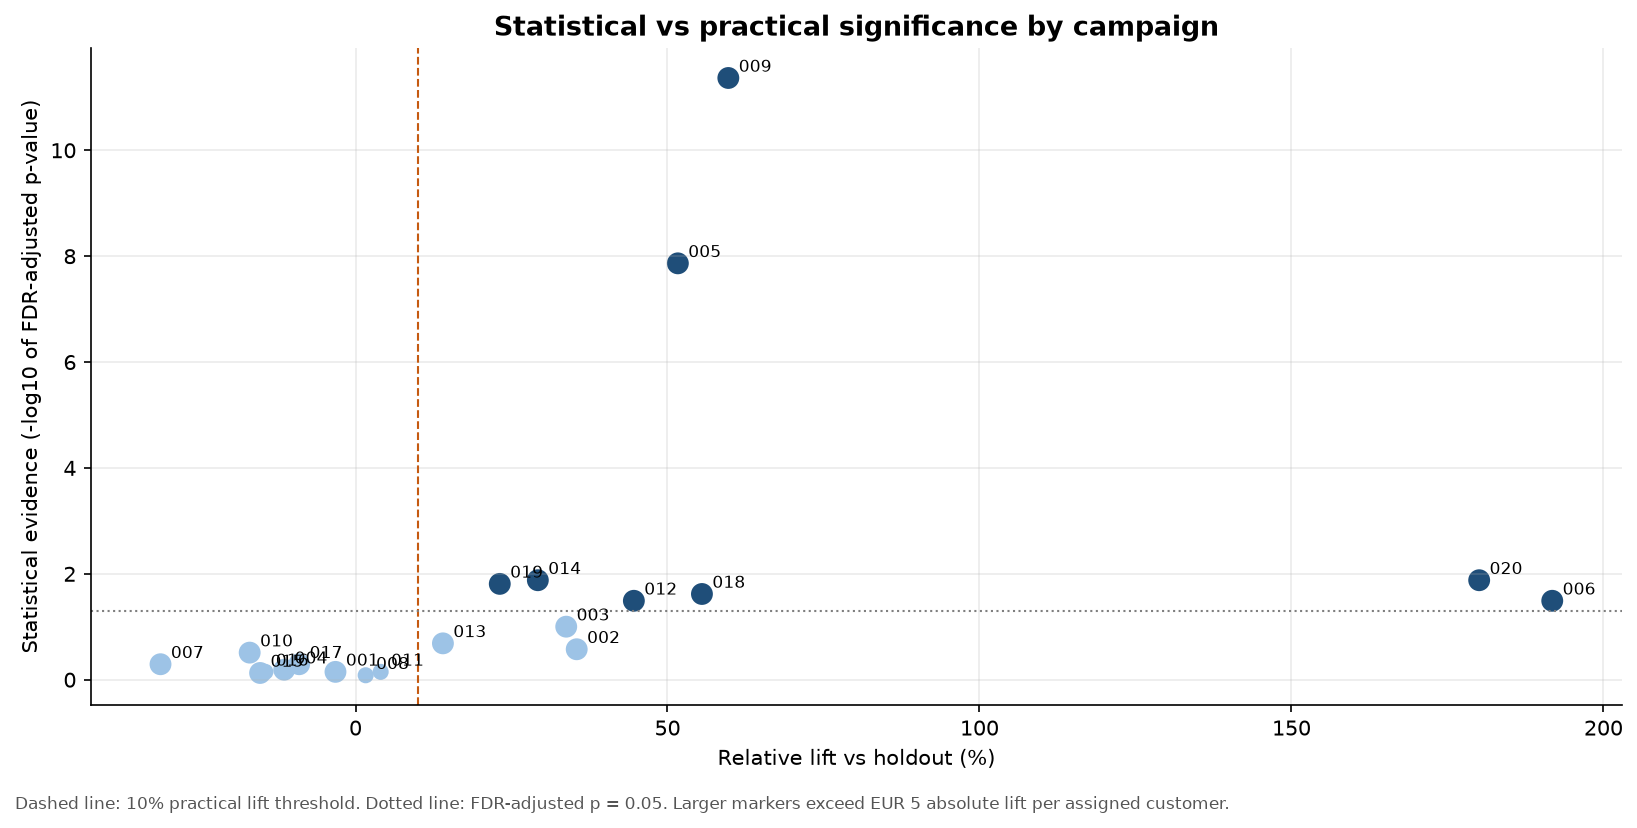

In [8]:
display(Image(filename=str(figures["campaign_significance_overview"])))

## 5. Post-hoc validation against the generator (not used in the analysis)

The dataset was generated with a known design: some campaigns were given a true lift and some
were placebos. This cell exists only to check that the frozen method behaves as it should - it
does not feed any number above, and the method was fixed in code before this notebook ran.
Toggle it off if you prefer to work with observed data only.

In [9]:
import json
from pathlib import Path

manifest_path = Path("..") / "data" / "generation_metadata" / "generation_manifest.json"
if manifest_path.is_file():
    ground_truth = pd.DataFrame(
        json.loads(manifest_path.read_text(encoding="utf-8"))["campaign_ground_truth"]
    ).set_index("campaign_id")[["is_placebo", "true_purchase_lift"]]
    check = statistics.set_index("campaign_id")[["statistically_significant"]].join(
        ground_truth, how="inner"
    )
    if check.empty:
        print("No campaign overlap between the analysis and the generator manifest.")
    else:
        print("Campaigns compared                    :", len(check))
        print("Placebo campaigns flagged significant :",
              int(check.loc[check['is_placebo'], 'statistically_significant'].sum()),
              "of", int(check['is_placebo'].sum()))
        print("Lifted campaigns detected             :",
              int(check.loc[~check['is_placebo'], 'statistically_significant'].sum()),
              "of", int((~check['is_placebo']).sum()))
else:
    print("Generation manifest not found; skipping the generator validation.")

Campaigns compared                    : 20
Placebo campaigns flagged significant : 0 of 9
Lifted campaigns detected             : 8 of 11


## 6. Limitations

* The dataset **simulates randomised campaign assignment**. Real client data often contains
  confounding, selection bias, targeting effects and non-random exposure, so these effect
  estimates are not automatically transferable.
* The primary estimate is intention-to-treat and is diluted by treatment-arm members who were
  never exposed; the exposure-only view is descriptive because it breaks the randomisation.
* Revenue is heavy-tailed. The bootstrap and rank-based checks are reported so a conclusion
  does not rest on a handful of large customers, but a single outlier can still move a mean.
* Statistical significance is not business significance, and the practical thresholds
  (10% relative, EUR 5 absolute) are business judgements, not statistical facts.
* Twenty campaigns are tested at once, so adjusted p-values are the ones to quote; the raw
  p-values are shown for transparency only.